# Psychrometrics and a cooling tower

`difflow.psychrometrics` is a differentiable humid-air library (ideal gas, ASHRAE constants, no enhancement
factor: $W_s$ sits 0.3-0.5 % below the real-gas ASHRAE table) and `CoolingTower` is a counterflow tower
designed and rated with the Merkel equation. **No ASHRAE table or textbook example was transcribed**; the
Merkel numbers quoted below (1.24, 1.39, 1.59, 1.89) are the illustration given in the issue for this
exercise (ideal-gas air, IAPWS saturation pressure, air saturated at the wet bulb, trapezoid rule), not
published values. The ice-line coefficients and the heat of fusion are recalled and flagged in the code.

In [1]:
import jax, jax.numpy as jnp, numpy as np
import matplotlib.pyplot as plt
jax.config.update("jax_enable_x64", True)
from difflow import CoolingTower, CoolingTowerParams, make_stream, maximum_L_over_G
from difflow.psychrometrics import *
from difflow.visualization import plot_psychrometric_chart
K = 273.15

## 1. Fix a state point from any two properties

In [2]:
s = state(T=303.15, RH=0.5)
for k in ("W", "RH", "T_wb", "T_dp", "h", "v", "mu"):
    print(f"{k:5s} {float(s[k]):12.5f}")
# the same state from a different pair of properties
b = state(T_wb=s["T_wb"], h=s["h"])
print("round trip T =", float(b["T"]) - K, "C")

W          0.01331
RH         0.50000
T_wb     295.15440
T_dp     291.59629
h      64216.91666
v          0.87717
mu         0.48930


round trip T = 30.0000000000025 C


## 2. Wet bulb vs. adiabatic saturation (Lewis relation)

With the Lewis factor $Le_f = h_c/(k_y c_s) = 1$ the two temperatures coincide for this model; the sidebar
parameter `lewis` moves the psychrometer wet bulb.

In [3]:
T, W = s["T"], s["W"]
print("adiabatic saturation:", float(adiabatic_saturation_temperature(T, W)) - K)
for le in (0.8, 0.9, 1.0, 1.1):
    print(f"wet bulb, Le_f = {le}:", round(float(wet_bulb_temperature(T, W, lewis=le)) - K, 3))

adiabatic saturation: 22.004401417206907


wet bulb, Le_f = 0.8: 21.511


wet bulb, Le_f = 0.9: 21.766


wet bulb, Le_f = 1.0: 22.004


wet bulb, Le_f = 1.1: 22.227


## 3. The chart, and a cold-room process (cool and dehumidify, then reheat)

coil leaves 12.0 C, RH 97%; duty 37.4 kW (latent 19.4, sensible 18.0); condensate 7.57 g/kg
reheated to 15.0 C, RH 80%


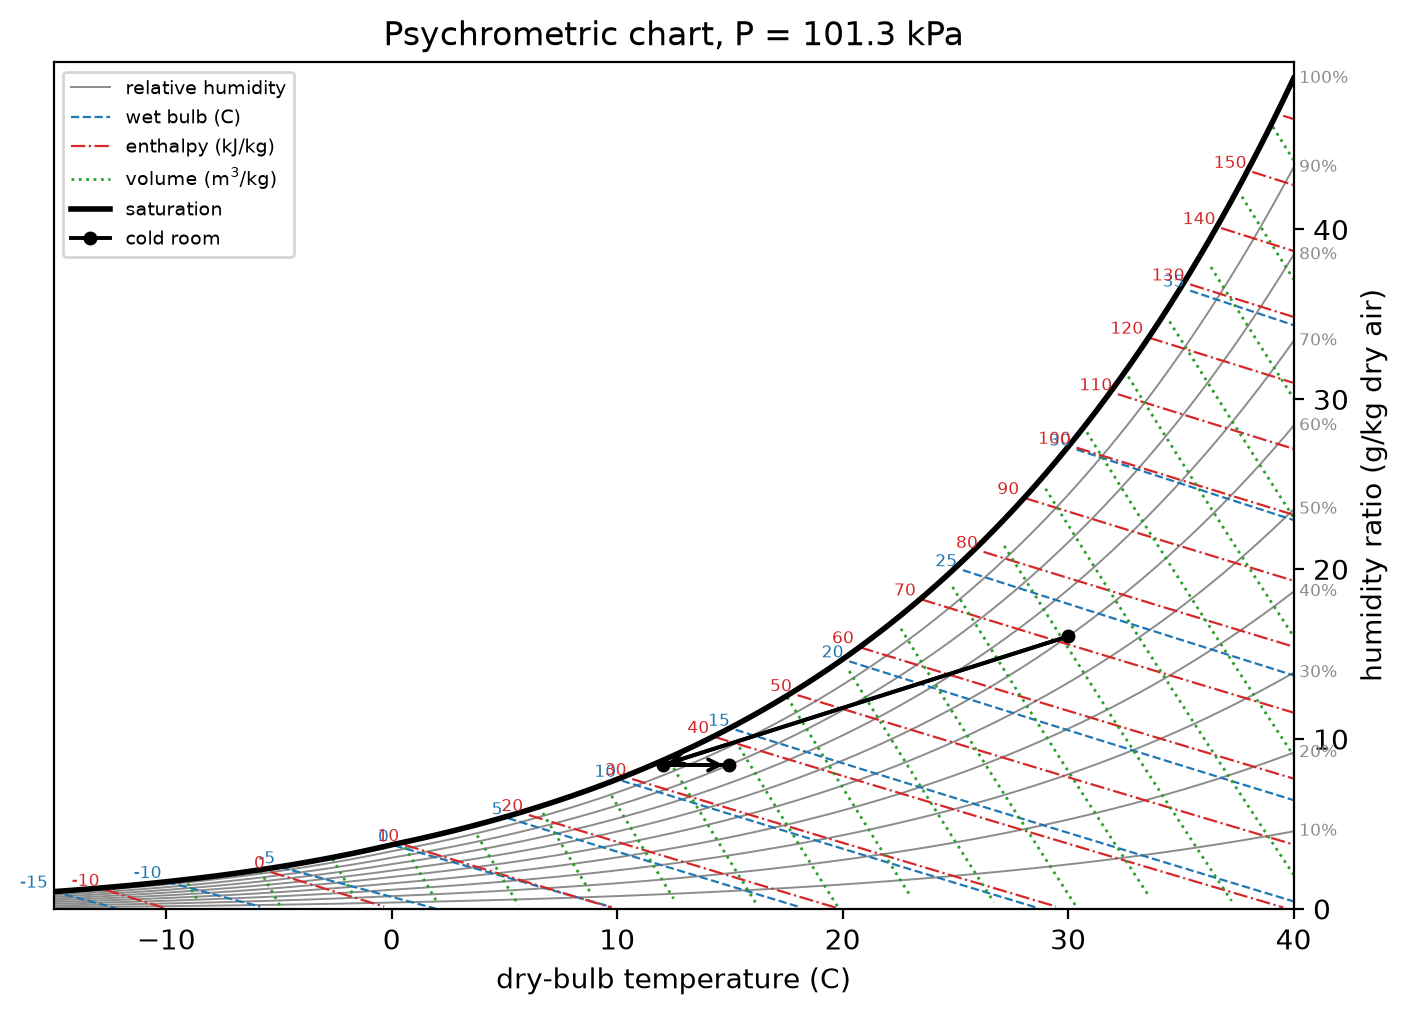

In [4]:
warm = state(T=303.15, RH=0.6)
cold, coil = cool_dehumidify(warm, T_coil=283.15, bypass_factor=0.1)
final = sensible_heat(cold, Q=3.0e3, m_dry_air=1.0)
print(f"coil leaves {float(cold['T'])-K:.1f} C, RH {float(cold['RH']):.0%}; duty {float(coil['Q_total'])/1e3:.1f} kW "
      f"(latent {float(coil['Q_latent'])/1e3:.1f}, sensible {float(coil['Q_sensible'])/1e3:.1f}); "
      f"condensate {float(coil['condensate'])*1e3:.2f} g/kg")
print(f"reheated to {float(final['T'])-K:.1f} C, RH {float(final['RH']):.0%}")
data = psychrometric_chart_data(T_range=(258.15, 313.15))
ax = plot_psychrometric_chart(data, processes=[{"states": [warm, cold, final], "label": "cold room"}])
plt.show()

## 4. The wex18-1 tower: 10 MW, 35 to 27 C at a 22 C wet bulb

The Merkel number at four water-to-air ratios with the CTI four-point method, against fine Gauss-Legendre
quadrature and an independent trapezoid integration.

In [5]:
L = 10e6 / (4186.0 * 8.0)                       # kg/s
hot = make_stream({"H2O": L / MW_WATER}, 35.0 + K, 3e5)
h_in = float(saturation_enthalpy(22.0 + K))

def trapezoid(lg, n=4001):
    x = np.linspace(0, 1, n)
    hs = np.asarray(saturation_enthalpy(jnp.asarray(27 + K + 8 * x)))
    return float(np.trapezoid(4186 * 8 / (hs - (h_in + lg * 4186 * 8 * x)), x))

print("L/G   CTI 4-pt   Gauss-16   trapezoid")
for lg in (0.8, 1.0, 1.2, 1.4):
    cti = float(CoolingTower(CoolingTowerParams(mode="design", L_over_G=lg, T_out=27 + K))(hot, T_wb=22 + K)[2]["KaV_L"])
    g16 = float(CoolingTower(CoolingTowerParams(mode="design", L_over_G=lg, T_out=27 + K, quadrature="gauss", n_quad=16))(hot, T_wb=22 + K)[2]["KaV_L"])
    print(f"{lg:.1f}   {cti:.4f}     {g16:.4f}     {trapezoid(lg):.4f}")

L/G   CTI 4-pt   Gauss-16   trapezoid


0.8   1.2413     1.2411     1.2411


1.0   1.3874     1.3878     1.3878


1.2   1.5878     1.5887     1.5887


1.4   1.8865     1.8878     1.8878


In [6]:
tower = CoolingTower(CoolingTowerParams(mode="design", L_over_G=1.2, T_out=27 + K))
cold, air_out, info = tower(hot, T_wb=22 + K)
for k in ("KaV_L", "range", "approach", "effectiveness", "evaporation", "drift", "blowdown", "makeup", "L_over_G_max"):
    print(f"{k:14s} {float(info[k]):10.4f}")
print("air leaves at", round(float(air_out['T']) - K, 2), "C, saturated")

KaV_L              1.5878
range              8.0000
approach           5.0000
effectiveness      0.6154
evaporation        3.0080
drift              0.0597
blowdown           0.9429
makeup             4.0106
L_over_G_max       1.9282
air leaves at 30.93 C, saturated


## 5. Pinch: what happens when L/G is too high

In [7]:
lgmax = float(maximum_L_over_G(35 + K, 27 + K, h_in))
for f in (0.5, 0.9, 0.99, 1.05):
    i = CoolingTower(CoolingTowerParams(mode="design", L_over_G=f * lgmax, T_out=27 + K))(hot, T_wb=22 + K)[2]
    print(f"L/G = {f*lgmax:.2f} ({f:.2f} x limit): KaV/L = {float(i['KaV_L']):.3f}, feasible = {bool(i['feasible'])}")

L/G = 0.96 (0.50 x limit): KaV/L = 1.358, feasible = True


L/G = 1.74 (0.90 x limit): KaV/L = 3.097, feasible = True


L/G = 1.91 (0.99 x limit): KaV/L = 6.961, feasible = True


L/G = 2.02 (1.05 x limit): KaV/L = inf, feasible = False


## 6. Approach vs. tower size, with gradients

Fill volume at a fixed volumetric coefficient `Ka` (kg/(m$^3$ s)), $V = (KaV/L)\,L/Ka$, against the approach
to the wet bulb, and its derivative by automatic differentiation.

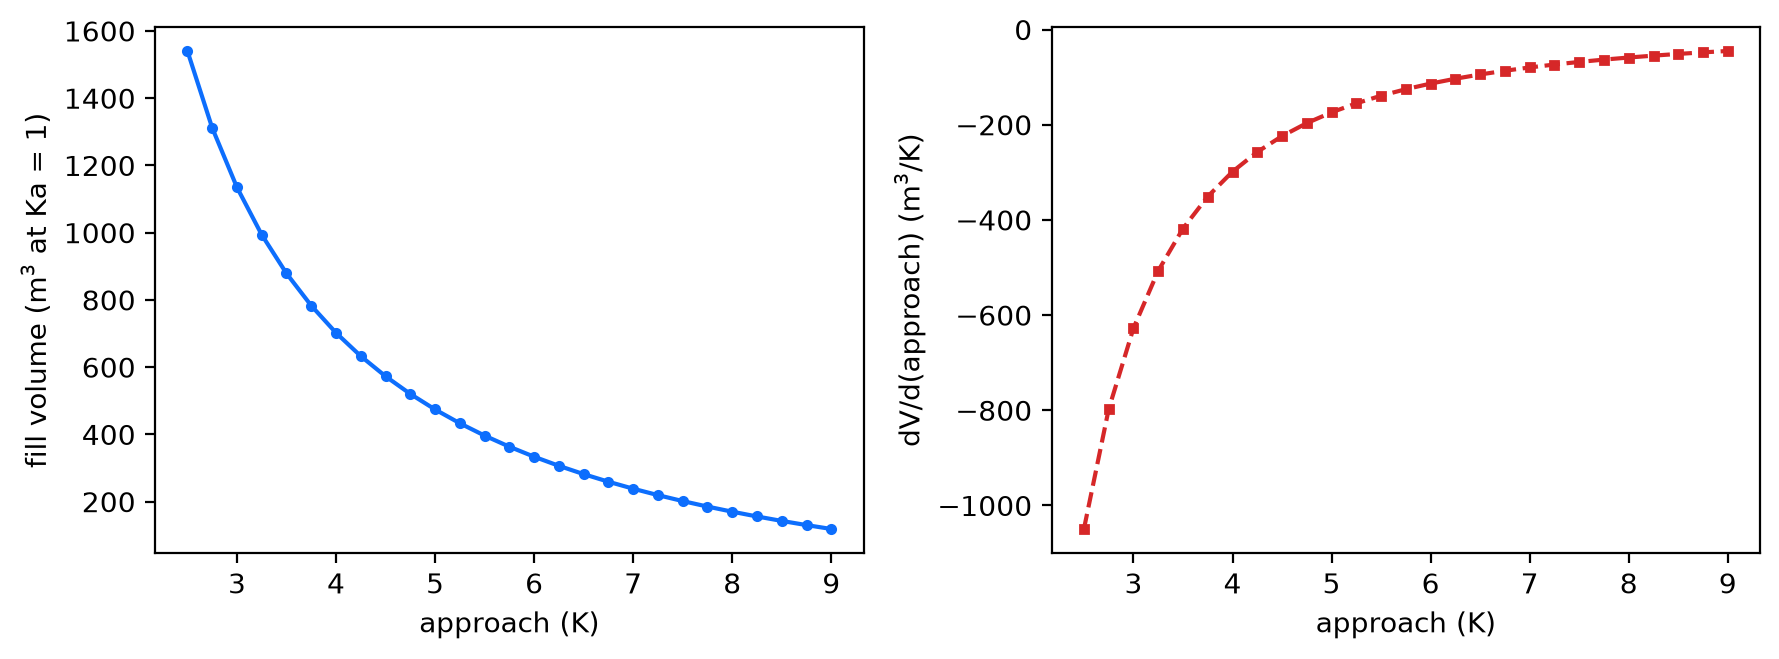

dV/d(approach) at 5 K: -173.95802953986922 ; dV/d(L/G) at 1.2: 356.65671427861383


In [8]:
def volume(approach, lg=1.2):
    t = CoolingTower(CoolingTowerParams(mode="design", L_over_G=lg, approach=approach, Ka=1.0))
    return t(hot, T_wb=22 + K)[2]["V"]

ap = np.linspace(2.5, 9.0, 27)
V = np.array([float(volume(a)) for a in ap])
dV = np.array([float(jax.grad(volume)(a)) for a in ap])
fig, ax = plt.subplots(1, 2, figsize=(9, 3.4))
ax[0].plot(ap, V, "-o", ms=3); ax[0].set_xlabel("approach (K)"); ax[0].set_ylabel("fill volume (m$^3$ at Ka = 1)")
ax[1].plot(ap, dV, "--s", ms=3, color="tab:red"); ax[1].set_xlabel("approach (K)"); ax[1].set_ylabel("dV/d(approach) (m$^3$/K)")
plt.tight_layout(); plt.show()
print("dV/d(approach) at 5 K:", float(jax.grad(volume)(5.0)), "; dV/d(L/G) at 1.2:", float(jax.grad(lambda g: volume(5.0, g))(1.2)))

## 7. Rating a fixed tower on a hot day

In [9]:
rate = CoolingTower(CoolingTowerParams(mode="rating", L_over_G=1.2, KaV_L=1.6))
for twb in (18.0, 22.0, 26.0):
    i = rate(hot, T_wb=twb + K)[2]
    print(f"wet bulb {twb:4.1f} C -> cold water {float(i['T_out'])-K:6.2f} C (approach {float(i['approach']):.2f} K)")
print("d T_out/d KaV_L:", float(jax.grad(lambda k: CoolingTower(CoolingTowerParams(mode='rating', L_over_G=1.2, KaV_L=k))(hot, T_wb=22 + K)[2]['T_out'])(1.6)))

wet bulb 18.0 C -> cold water  25.19 C (approach 7.19 K)


wet bulb 22.0 C -> cold water  26.98 C (approach 4.98 K)


wet bulb 26.0 C -> cold water  29.05 C (approach 3.05 K)


d T_out/d KaV_L: -1.69965742881013
